# Paulstretch/Arbitrary Phase Reconstruction
Paulstretch is an extreme time stretching algorithm created by Paul Nasca that utilizes arbitrary phase reconstruction. On a high level, the algorithm works by first dividing an audio segment into several smaller windows. Window size is dictated by the user. Then, the Fast Fourier Transform (FFT) is applied to each window; the phase information of each window is randomized; and the Inverse Fourier Transform is applied to each window. The final step produces the time stretching effect: the windows are added back together, overlapping, and spaced out differently than they are in the input.

The diagram below visualises these steps.

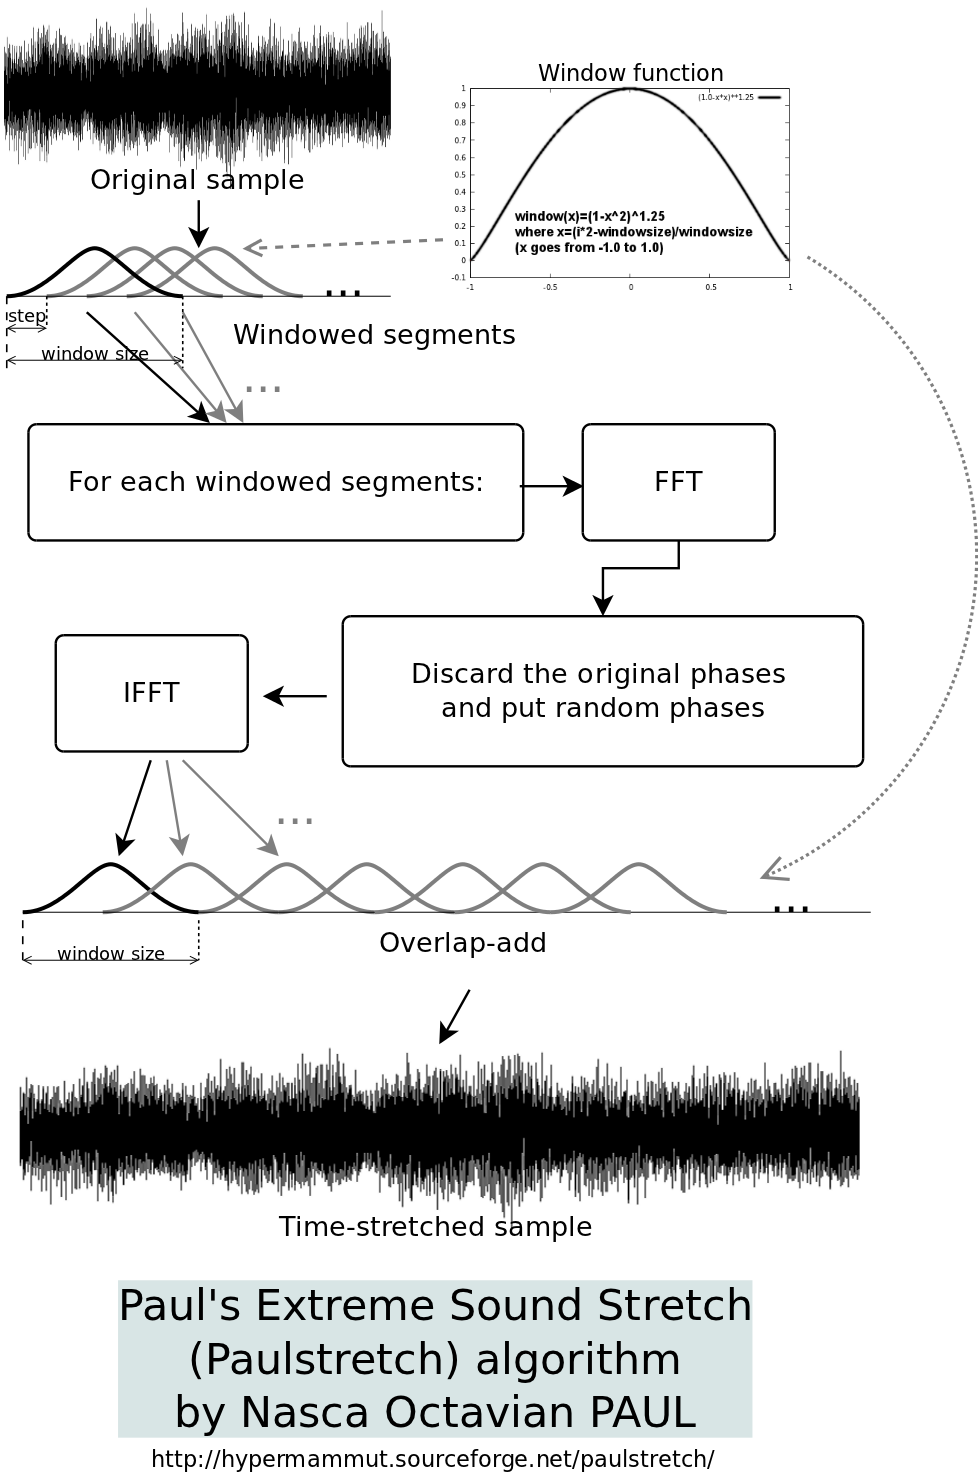

In [11]:
import numpy as np
import scipy.fft as fft
import IPython.display as ipd
import scipy.io.wavfile as wavfile
import matplotlib.pyplot as plt

# use this filename when working locally
filename = '/content/tomsdiner_mono.wav'
# use this filename when working within github
#filename = '../../data/tomsdiner_mono.wav'
srate, tomsdiner = wavfile.read(filename)
ipd.Audio(tomsdiner, rate=srate)

# the code below is adapted from the Paulstretch python implementation by Paul Nasca

def paulstretch(samplerate, sample, winsize_sec, stretch, outputname):
    # calculate window size in samples
    winsize = int(winsize_sec*samplerate)
    if winsize<16:
        winsize=16
    winsize=int(winsize/2)*2
    half_winsize = int(winsize/2)

    #correct end of sample
    end_size=int(samplerate*0.05)
    if end_size<16:
        end_size=16
    sample[len(sample)-end_size:len(sample)]*=np.linspace(1,0,end_size)

    # calculate displacement in the input audio file
    start_pos=0.0
    displace_pos=(winsize*0.5)/stretch

    #create Hann window
    window=0.5-np.cos(np.arange(winsize,dtype='float')*2.0*np.pi/(winsize-1))*0.5
    old_windowed_buf=np.zeros(winsize)
    hinv_sqrt2=(1+np.sqrt(0.5))*0.5
    hinv_buf=hinv_sqrt2-(1.0-hinv_sqrt2)*np.cos(np.arange(half_winsize,dtype='float')*2.0*np.pi/half_winsize)

    while True:

        #get the windowed buffer
        istart_pos=int(np.floor(start_pos))
        buf=sample[istart_pos:istart_pos+winsize]
        if np.len(buf)<winsize:
            buf=np.append(buf,np.zeros(winsize-len(buf)))
        buf=buf*window

        #get the amplitudes of the frequency components and discard the phases
        freqs=abs(fft.rfft(buf))

        #randomize the phases by multiplication with a random complex number with modulus=1
        ph=np.random.uniform(0,2*np.pi,len(freqs))*1j
        freqs=freqs*np.exp(ph)

        #do the inverse FFT
        buf=fft.irfft(freqs)

        #window again the output buffer
        buf*=window

        #overlap-add the output
        output=buf[0:half_winsize]+old_windowed_buf[half_winsize:winsize]
        old_windowed_buf=buf

        #remove the resulted amplitude modulation
        output*=hinv_buf

        #clamp the values to -1..1
        output[output>1.0]=1.0
        output[output<-1.0]=-1.0

    # output = (create np array)
    wavfile.write(outputname, samplerate, output)

    ## code unfinished





# References
https://hypermammut.sourceforge.net/paulstretch/

Laptew, E., & Lu, Y. (2023, December). Work in Progress: A Simple Plug-in Implementation of Extreme Audio Stretching. In 2023 IL-IN Section Conference.

https://www.paulnasca.com/algorithms-created-by-me#TOC-PaulStretch-extreme-sound-

https://github.com/paulnasca/paulstretch_cpp$0

https://github.com/paulnasca/paulstretch_python/blob/master/paulstretch_mono.py$0